<a href="https://colab.research.google.com/github/Andrew-lee0615/value-at-risk-analysis/blob/main/02_historical_var.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd
import yfinance as yf


In [4]:

tickers = ["NVDA","INTC", "AMD", "MU", "MRVL", "WDC", "AVGO", "SPY"]
prices = yf.download(tickers, period="5y", auto_adjust=True)["Close"]
prices.tail()


[*********************100%***********************]  8 of 8 completed


Ticker,AMD,AVGO,INTC,MRVL,MU,NVDA,SPY,WDC
Date,,,,,,,,
2026-10-12,594.239990,354.730011,101.349998,265.859985,988.884338,226.320007,778.099976,386.940002
2026-10-13,605.530029,357.309998,102.809998,268.730011,953.040039,228.520004,778.010010,380.709991
2026-10-14,570.820007,346.250000,98.120003,245.279999,914.130005,221.300003,769.599976,364.100006
2026-10-15,562.229980,344.329987,95.370003,241.240005,931.239990,217.229996,771.789978,356.450012
2026-10-16,528.750000,328.750000,89.849998,227.830002,878.840027,214.130005,763.250000,332.000000


In [5]:
log_returns = np.log(prices / prices.shift(1)).dropna()
log_returns.head()

Ticker,AMD,AVGO,INTC,MRVL,MU,NVDA,SPY,WDC
Date,,,,,,,,
2021-10-19,-0.000859,0.013870,0.013494,0.010073,0.004598,0.003055,0.007686,0.004503
2021-10-20,0.000516,-0.001961,0.002894,-0.009775,0.010306,-0.008425,0.003920,0.013564
2021-10-21,0.024946,0.009301,0.011314,-0.001787,0.005405,0.026299,0.002605,0.006890
2021-10-22,0.004098,0.002447,-0.124187,-0.011396,-0.016600,0.001497,-0.001037,0.004392
2021-10-25,0.020977,0.012839,-0.001011,0.020302,0.018346,0.019176,0.005348,-0.003864


In [10]:
-np.percentile(log_returns["SPY"], 1)


np.float64(0.02972838371795713)

In [11]:
-log_returns.quantile(0.05)

,0.05
Ticker,
AMD,0.056721
AVGO,0.040524
INTC,0.053766
MRVL,0.059904
MU,0.049143
NVDA,0.049230
SPY,0.016589
WDC,0.049818


In [12]:
-log_returns.quantile(0.01)

,0.01
Ticker,
AMD,0.087115
AVGO,0.068342
INTC,0.086954
MRVL,0.104616
MU,0.091671
NVDA,0.077447
SPY,0.029728
WDC,0.094532


In [13]:
stocks = ["NVDA","INTC","AMD","MU","MRVL","WDC","AVGO"]
port = log_returns[stocks].mean(axis=1)
port.head()

,0
Date,
2021-10-19,0.006962
2021-10-20,0.001017
2021-10-21,0.011767
2021-10-22,-0.019964
2021-10-25,0.012395


In [16]:
port_var_95 = -port.quantile(0.05)
port_var_99 = -port.quantile(0.01)
print(port_var_95)
print(port_var_99)


0.04230159771014731
0.06934888399931227


## Key Finding
Diversifying across 7 semiconductor names cut the 99% VaR by about 20% (8.72% → 6.93%), but the portfolio still carried 2.3x the market's risk (SPY 2.97%), because the stocks are highly correlated.


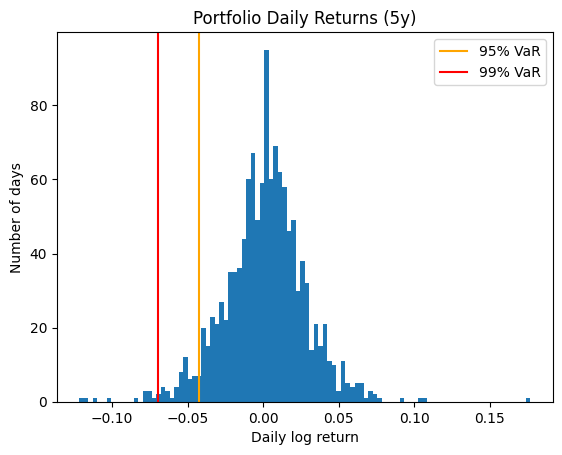

In [20]:
import matplotlib.pyplot as plt

plt.hist(port, bins=100)
plt.axvline(-port_var_95, color="orange", label="95% VaR")
plt.axvline(-port_var_99, color="red", label="99% VaR")
plt.legend()
plt.title("Portfolio Daily Returns (5y)")
plt.xlabel("Daily log return")
plt.ylabel("Number of days")
plt.show()